# 00 · Gruson pipeline walkthrough (raw spectra → one fitted sweep)

This notebook follows **one brightness sweep** of *M. aega* (session 2026-10-21) through every step of the pipeline, so you can see what each operation does. The full pipeline (all species and sessions) is `python -m morpho_gruson.cli run`; see `docs/methods.md`.

**Steps:** raw intensity → Savitzky–Golay smoothing → division by the nearest white reference → masking of the 523–534 nm artefact → mean reflectance (brightness) → Gaussian fit.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np, matplotlib.pyplot as plt
from morpho_gruson.pipeline import load_config, RawStore, reference_pool, _cluster
from morpho_gruson.io import parse_columns
from morpho_gruson.signal import smooth, mask_band, nearest_reference
from morpho_gruson.models import brightness_model
from scipy.optimize import curve_fit
cfg = load_config("../gruson/config/pipeline.yaml")
store = RawStore("../gruson/data/raw")
sg, band = cfg["signal"]["savgol"], cfg["signal"]["masked_band_nm"]
lo, hi = cfg["signal"]["wavelength_range_nm"]
print("Savitzky–Golay:", sg, "| masked band (nm):", band, "| range (nm):", (lo, hi))

Savitzky–Golay: {'window': 151, 'polyorder': 3} | masked band (nm): [523, 534] | range (nm): (400, 700)


## 1. White-reference pool
Every spectrum is divided by the white reference measured at the closest (I, C) geometry. The pool merges the references of two sessions (36 unique geometries).

In [2]:
pool = reference_pool(cfg, store)
print(len(pool), "reference geometries (I, C):")
print(sorted(pool))

36 reference geometries (I, C):
[(-15, 25), (-12, 22), (-10, 25), (-5, 25), (0, 25), (0, 45), (5, 5), (5, 25), (5, 35), (7, 3), (10, 10), (10, 25), (10, 30), (15, 15), (15, 25), (18, 52), (20, 5), (20, 10), (20, 15), (20, 20), (20, 25), (20, 30), (20, 35), (20, 40), (20, 45), (20, 50), (25, 15), (25, 25), (30, 10), (30, 25), (30, 30), (35, 5), (35, 25), (37, 33), (40, 10), (40, 25)]


## 2. Pick one sweep
A **brightness** sweep keeps the span I+C constant and varies the bisector (I−C)/2. Here: *M. aega*, replicate 9, I+C = 40°.

In [3]:
wl, data = store.get("2026-10-21_session.xlsx")
recs, _ = parse_columns(list(data))
pts = [p for p in recs[("aega", "9")] if p[0] == "brightness"]
print(len(pts), "spectra; example raw column name:", pts[0][3])
m = (wl >= lo) & (wl <= hi); w = wl[m]
geoms = sorted(pool)

7 spectra; example raw column name: aega9_brillo_I13C27.RAW8


## 3. Cleaning one spectrum, step by step

column 'aega9_brillo_I18C22.RAW8': I=18, C=22 -> nearest white reference (I, C) = (20, 20)
Brightness of this spectrum = mean reflectance 400–700 nm = 1.893


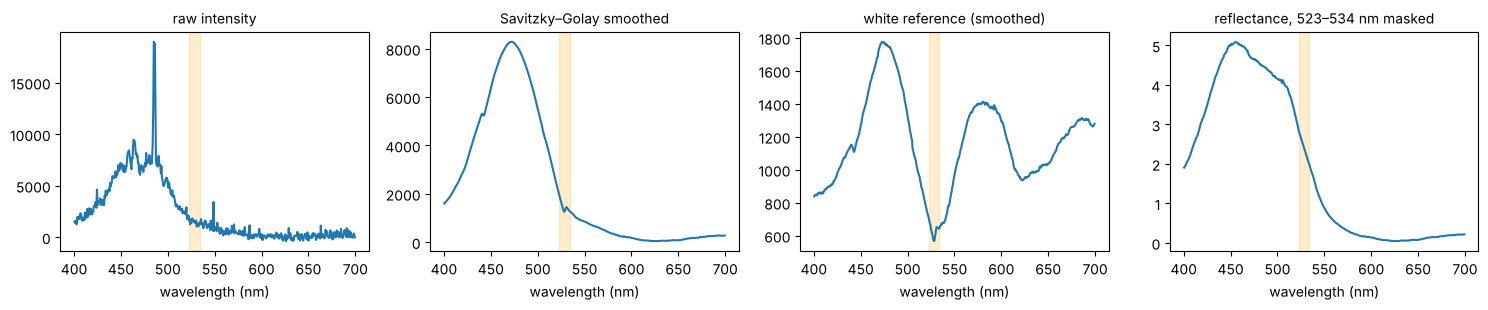

In [4]:
kind, I, C, h = min(pts, key=lambda p: abs((p[1]-p[2])/2 + 3))   # spectrum nearest the brightness peak
raw = data[h][m]
sm = smooth(data[h], sg["window"], sg["polyorder"])[m]
g = nearest_reference(I, C, geoms); ref = pool[g]
refl = sm / ref
clean = mask_band(w, refl, band)
print(f"column {h!r}: I={I}, C={C} -> nearest white reference (I, C) = {g}")
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, (y, t) in zip(ax, [(raw, "raw intensity"), (sm, "Savitzky–Golay smoothed"), (ref, "white reference (smoothed)"), (clean, "reflectance, 523–534 nm masked")]):
    a.plot(w, y, lw=1.5); a.set_title(t, fontsize=10); a.set_xlabel("wavelength (nm)"); a.axvspan(*band, color="orange", alpha=.2)
plt.tight_layout()
print("Brightness of this spectrum = mean reflectance 400–700 nm =", round(float(np.nanmean(clean)), 3))

## 4. All spectra of the sweep → brightness vs bisector → Gaussian fit

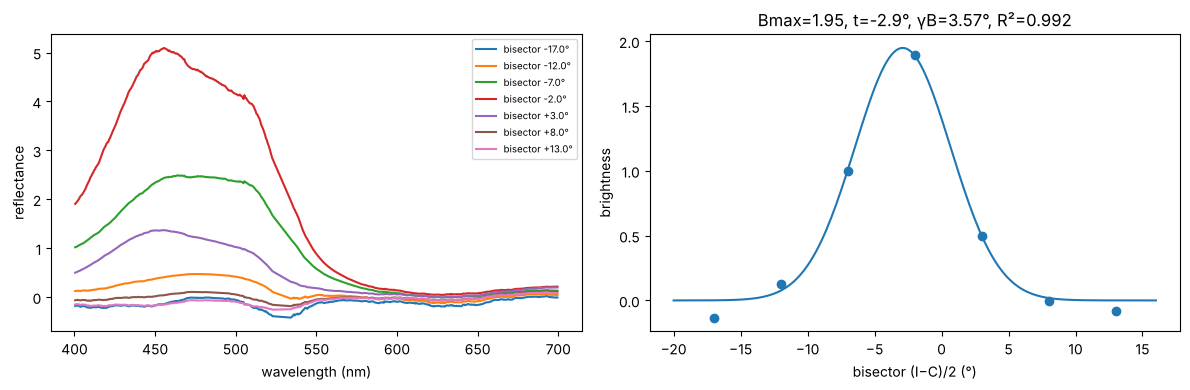

In [5]:
xs, ys = [], []
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for kind, I, C, h in sorted(pts, key=lambda p: p[1]-p[2]):
    sm = smooth(data[h], sg["window"], sg["polyorder"])[m]
    r = mask_band(w, sm / pool[nearest_reference(I, C, geoms)], band)
    xs.append((I - C) / 2); ys.append(np.nanmean(r)); ax[0].plot(w, r, label=f"bisector {(I-C)/2:+.1f}°")
ax[0].set_xlabel("wavelength (nm)"); ax[0].set_ylabel("reflectance"); ax[0].legend(fontsize=7)
x, y = np.array(xs), np.array(ys)
po, _ = curve_fit(brightness_model, x, y, p0=[y.max(), x[np.argmax(y)], 10], bounds=([0, -45, .5], [np.inf, 45, 60]))
r2 = 1 - ((y - brightness_model(x, *po))**2).sum() / ((y - y.mean())**2).sum()
xx = np.linspace(x.min()-3, x.max()+3, 200)
ax[1].scatter(x, y, zorder=3); ax[1].plot(xx, brightness_model(xx, *po)); ax[1].set_xlabel("bisector (I−C)/2 (°)"); ax[1].set_ylabel("brightness")
ax[1].set_title(f"Bmax={po[0]:.2f}, t={po[1]:.1f}°, γB={po[2]:.2f}°, R²={r2:.3f}")
plt.tight_layout()

## 5. Acceptance
A sweep is kept only if it passes the criteria in `config/pipeline.yaml` (`acceptance`: R² ≥ 0.75, ≥ 5 points, physically plausible parameters) and is not in `manual_exclusions`. Hue sweeps follow the same logic with the peak-centroid wavelength and the cosine model; species without a spectral peak (*eugenia*, *marcus*, *anaxibia*) use the spectral-edge position instead.